# 2 · Hypothetical fixed-price contract simulator

**Can either DA forecast add value against an assumed counterparty quote after costs?**

This is a financially settled contract on a specified quarter-hour's DA price, **not a Nord Pool DA order**, physical electricity position, or DA-to-ID trade. At an assumed previous-day decision time, a counterparty quotes a bid and ask. A bought contract pays DA price minus execution price; a sold contract pays the reverse. Settlement is automatic, so no ID prices or closing trade are needed.

The quote midpoint is a calendar-mean benchmark fitted only on the prediction training set. Quotes and full fills are hypothetical, with no default, collateral or funding costs. The benchmark can be unusually easy or difficult to beat; results are conditional on this assumption. Weather forecast vintages remain unverified.

Run `da_prediction.ipynb` or `da_prediction.py` first. This notebook is standalone: no `.py` files are needed. It reads only the prediction CSV and metadata exported in Part 1. Part 2 does **not retrain** anything and does not import XGBoost or fetch market data.


## Dependencies

If needed, uncomment and run the installation cell. Restart the kernel after installing, then run all cells from the top.

In [22]:
# %pip install numpy pandas plotly

## Embedded implementation

All functions are included here; no local `.py` imports are needed.

In [23]:
import argparse
from dataclasses import dataclass, asdict
import hashlib
import json
from pathlib import Path
import numpy as np
import pandas as pd

In [24]:
@dataclass(frozen=True)
class ContractConfig:
    spread_eur_mwh: float = 4.0  # FULL bid-ask width; half charged on either side
    slippage_eur_mwh: float = 0.5
    fee_eur_mwh: float = 0.5  # TOTAL contract fee; no closing transaction at settlement
    risk_buffer_eur_mwh: float = 5.0
    max_mw_per_interval: float = 1.0
    max_daily_gross_mwh: float = 10.0
    stress_move_eur_mwh: float = 100.0
    daily_stress_budget_eur: float = 500.0

In [25]:
def validate_config(cfg):
    for field,value in asdict(cfg).items():
        if not np.isfinite(value) or value < 0:
            raise ValueError(f'{field} must be finite and nonnegative.')
    if cfg.stress_move_eur_mwh <= 0:
        raise ValueError('Stress price move must be strictly positive.')

In [26]:
def load_bundle(directory):
    """Load the held-out forecast contract; check metadata and content integrity."""
    directory=Path(directory)
    metadata=json.loads((directory/'metadata.json').read_text(encoding='utf-8'))
    csv=directory/'test_predictions.csv'
    if metadata.get('schema_version')!=1:
        raise ValueError('Unsupported prediction export schema.')
    if hashlib.sha256(csv.read_bytes()).hexdigest()!=metadata.get('predictions_sha256'):
        raise ValueError('Prediction CSV and metadata do not match; re-export predictions.')
    frame=pd.read_csv(csv)
    required={'delivery_start_utc','actual_da','pred_weather','pred_fundamentals','quote_mid',
              'decision_time_utc','duration_hours','eligible_for_contract','high_price'}
    if not required.issubset(frame.columns):
        raise ValueError(f'Missing columns: {required-set(frame.columns)}')
    frame.index=pd.to_datetime(frame.pop('delivery_start_utc'),utc=True)
    frame.index.name='delivery_start_utc'
    frame['decision_time_utc']=pd.to_datetime(frame.decision_time_utc,utc=True)
    if frame.index.has_duplicates or not frame.index.is_monotonic_increasing:
        raise ValueError('Predictions must have sorted unique delivery timestamps.')
    numeric=['actual_da','pred_weather','pred_fundamentals','quote_mid','duration_hours']
    if not np.isfinite(frame[numeric].to_numpy(dtype=float)).all():
        raise ValueError('Prediction bundle has missing/non-finite numbers.')
    if not np.allclose(frame.duration_hours,.25):
        raise ValueError('Expected 15-minute delivery contracts.')
    for col in ['eligible_for_contract','high_price']:
        values=frame[col].astype(str).str.lower()
        if not values.isin(['true','false']).all():
            raise ValueError(f'Invalid boolean column: {col}')
        frame[col]=values.eq('true')
    assumed_fit=pd.Timestamp(metadata['training_labels_available_assumed_utc'])
    expected=frame.decision_time_utc>assumed_fit
    if not np.array_equal(expected.to_numpy(),frame.eligible_for_contract.to_numpy()):
        raise ValueError('Trading eligibility is inconsistent with training completion.')
    if not (frame.decision_time_utc<frame.index).all():
        raise ValueError('Decision times must precede delivery.')
    if len(frame)!=metadata['n_test'] or frame.index.min()<=pd.Timestamp(metadata['train_end']):
        raise ValueError('Export is not the declared held-out period.')
    return frame,metadata

In [27]:
def plan_positions(signals, cfg, timezone):
    """Pre-decision inputs ONLY. No actual prices, high-price flags or realised P&L.

    Every delivery day's positions are chosen together. Rank opportunities by
    expected margin after costs; allocate subject to daily gross volume and a
    conservative stress exposure proxy. This is not a realised daily stop-loss.
    """
    validate_config(cfg)
    allowed={'prediction','quote_mid','duration_hours','decision_time_utc'}
    if set(signals.columns)!=allowed:
        raise ValueError('Planner accepts only prediction, quote, duration and decision time.')
    if not signals.index.is_unique:
        raise ValueError('Signals need unique timestamps.')
    if not np.isfinite(signals[['prediction','quote_mid','duration_hours']]).all().all():
        raise ValueError('Signals contain non-finite numbers.')
    if (signals.duration_hours<=0).any():
        raise ValueError('Contract durations must be positive.')
    plan=signals.copy().sort_index()
    plan['delivery_day']=plan.index.tz_convert(timezone).strftime('%Y-%m-%d')
    plan['bid']=plan.quote_mid-cfg.spread_eur_mwh/2
    plan['ask']=plan.quote_mid+cfg.spread_eur_mwh/2
    plan['buy_edge']=plan.prediction-(plan.ask+cfg.slippage_eur_mwh)-cfg.fee_eur_mwh
    plan['sell_edge']=(plan.bid-cfg.slippage_eur_mwh)-plan.prediction-cfg.fee_eur_mwh
    plan['side']=np.where(plan.buy_edge>cfg.risk_buffer_eur_mwh,1,
                           np.where(plan.sell_edge>cfg.risk_buffer_eur_mwh,-1,0))
    plan['expected_edge']=np.maximum(plan.buy_edge,plan.sell_edge)
    plan['quantity_mwh']=0.0
    # Gross exposure means opposite trades cannot mask each other's risk.
    daily_cap=min(cfg.max_daily_gross_mwh,
                  cfg.daily_stress_budget_eur/cfg.stress_move_eur_mwh)
    for _,group in plan.groupby('delivery_day',sort=True):
        if group.decision_time_utc.nunique()!=1:
            raise ValueError('Each delivery day must share a single pre-auction decision time.')
        remaining=daily_cap
        ranked=group[group.side!=0].sort_values('expected_edge',ascending=False,kind='stable')
        for timestamp,row in ranked.iterrows():
            volume=min(cfg.max_mw_per_interval*row.duration_hours,remaining)
            if volume<=1e-12:
                break
            plan.at[timestamp,'quantity_mwh']=row.side*volume
            remaining-=volume
    plan['action']=np.select([plan.quantity_mwh>0,plan.quantity_mwh<0],['BUY','SELL'],default='NO_TRADE')
    executed_side=np.sign(plan.quantity_mwh)
    plan['execution_price']=np.where(executed_side!=0,
        plan.quote_mid+executed_side*(cfg.spread_eur_mwh/2+cfg.slippage_eur_mwh),np.nan)
    plan['fees_eur']=plan.quantity_mwh.abs()*cfg.fee_eur_mwh
    plan['expected_net_pnl_eur']=(plan.quantity_mwh*(plan.prediction-plan.execution_price)).fillna(0)-plan.fees_eur
    plan['stress_exposure_eur']=plan.quantity_mwh.abs()*cfg.stress_move_eur_mwh
    return plan

In [28]:
def settle_positions(plan, actual, cfg):
    """Only here are actual DA prices introduced. Signed Q handles long and short."""
    if not actual.index.equals(plan.index) or not np.isfinite(actual).all():
        raise ValueError('Settlement prices must align exactly with planned delivery intervals.')
    ledger=plan.copy()
    ledger['actual_da']=actual
    traded=ledger.quantity_mwh.ne(0)
    ledger['gross_pnl_eur']=np.where(traded,
        ledger.quantity_mwh*(ledger.actual_da-ledger.execution_price),0.)
    ledger['net_pnl_eur']=ledger.gross_pnl_eur-ledger.fees_eur
    ledger['cumulative_pnl_eur']=ledger.net_pnl_eur.cumsum()
    ledger['drawdown_eur']=ledger.cumulative_pnl_eur-ledger.cumulative_pnl_eur.cummax().clip(lower=0)
    # +/- stress moves are sensitivities, not predictions or maximum possible loss.
    ledger['pnl_change_if_da_up_stress']=ledger.quantity_mwh*cfg.stress_move_eur_mwh
    ledger['pnl_change_if_da_down_stress']=-ledger.quantity_mwh*cfg.stress_move_eur_mwh
    return ledger

In [29]:
def summarise(ledger, model):
    active=ledger[ledger.quantity_mwh!=0]
    gross_volume=ledger.quantity_mwh.abs().sum()
    n_days=ledger.delivery_day.nunique()
    daily=ledger.groupby('delivery_day').net_pnl_eur.sum()
    return dict(model=model,n_intervals=len(ledger),n_trades=len(active),n_days=n_days,
        long_trades=int((ledger.quantity_mwh>0).sum()),short_trades=int((ledger.quantity_mwh<0).sum()),
        gross_volume_mwh=gross_volume,net_pnl_eur=ledger.net_pnl_eur.sum(),
        fees_eur=ledger.fees_eur.sum(),
        pnl_per_traded_mwh=ledger.net_pnl_eur.sum()/gross_volume if gross_volume else np.nan,
        win_rate_pct=100*(active.net_pnl_eur>0).mean() if len(active) else np.nan,
        worst_day_eur=daily.min() if len(daily) else np.nan,
        losing_days=int((daily<0).sum()),
        max_drawdown_eur=-ledger.drawdown_eur.min() if len(ledger) else 0.)

In [30]:
def run_contract(frame, metadata, cfg):
    validate_config(cfg)
    eligible=frame[frame.eligible_for_contract].copy()
    if eligible.empty:
        raise ValueError('No contract-eligible observations after the training availability cutoff.')
    timezone=metadata['config']['timezone']
    ledgers=[]; summaries=[]; daily_parts=[]; regimes=[]
    for model in ['weather','fundamentals']:
        # Explicit allowlist prevents settlement prices from entering the planner.
        signals=eligible[[f'pred_{model}','quote_mid','duration_hours','decision_time_utc']].rename(
            columns={f'pred_{model}':'prediction'})
        plan=plan_positions(signals,cfg,timezone)
        ledger=settle_positions(plan,eligible.actual_da,cfg)
        ledger['model']=model
        ledger['high_price']=eligible.high_price
        summaries.append(summarise(ledger,model))
        daily=ledger.groupby('delivery_day').agg(net_pnl_eur=('net_pnl_eur','sum'),
            expected_net_pnl_eur=('expected_net_pnl_eur','sum'),
            gross_volume_mwh=('quantity_mwh',lambda x:x.abs().sum()),
            stress_exposure_eur=('stress_exposure_eur','sum'),n_intervals=('net_pnl_eur','size'))
        daily['model']=model
        daily_parts.append(daily.reset_index())
        for label,mask in [('all',pd.Series(True,index=ledger.index)),
                           ('high_price',ledger.high_price),('other',~ledger.high_price)]:
            part=ledger[mask]
            traded=part[part.quantity_mwh!=0]
            regimes.append(dict(model=model,regime=label,n_intervals=len(part),n_trades=len(traded),
                net_pnl_eur=part.net_pnl_eur.sum(),
                prediction_mae=(part.prediction-part.actual_da).abs().mean(),
                quote_mae=(part.quote_mid-part.actual_da).abs().mean()))
        ledgers.append(ledger)
    report={'config':asdict(cfg),'timezone':timezone,'synthetic':metadata['synthetic'],
        'forecast_vintages_verified':metadata['forecast_vintages_verified'],
        'excluded_unavailable_decisions':int((~frame.eligible_for_contract).sum()),
        'source_predictions_sha256':metadata['predictions_sha256'],
        'assumptions':['Hypothetical financially settled fixed-price contracts, not exchange DA orders',
         'Unlimited counterparty quote availability up to configured volume; no rejection/default/collateral costs',
         'Frozen training-only calendar mean is quote midpoint; both models face identical bid/ask quotes',
         'Orders selected before observing settlement prices; actual DA used only in settlement/evaluation',
         'Stress budget is exposure under an assumed adverse move, not a guaranteed loss cap',
         'Each model is a separate alternative strategy, not a combined portfolio',
         'Retrospective forecast vintages are unverified; hypothetical P&L is not demonstrated achievable profit',
         'Only complete-case forecast rows are scored; missing periods are not imputed',
         'Zero-trade cash benchmark has zero P&L; no interest or funding included']}
    return {'ledger':pd.concat(ledgers),'summary':pd.DataFrame(summaries),
            'daily':pd.concat(daily_parts,ignore_index=True),'regimes':pd.DataFrame(regimes),'report':report}

In [31]:
def export_contract(result,directory):
    directory=Path(directory); directory.mkdir(parents=True,exist_ok=True)
    result['ledger'].to_csv(directory/'trade_ledger.csv')
    for name in ['summary','daily','regimes']:
        result[name].to_csv(directory/f'{name}.csv',index=False)
    (directory/'assumptions.json').write_text(json.dumps(result['report'],indent=2),encoding='utf-8')
    return directory

In [32]:
def pnl_figure(result):
    import plotly.express as px
    return px.line(result['ledger'].reset_index(),x='delivery_start_utc',y='cumulative_pnl_eur',color='model',
        title='Hypothetical cumulative net P&L — not realised market trading',
        labels={'cumulative_pnl_eur':'EUR'},template='plotly_white')

In [33]:
def commercial_performance_figure(result):
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
    fig=make_subplots(rows=3,cols=1,shared_xaxes=True,vertical_spacing=.10,
        subplot_titles=['Cumulative settled net P&L','Daily net P&L','Drawdown from previous peak (starts at zero)'])
    for model,colour in [('weather','#2563eb'),('fundamentals','#d97706')]:
        ledger=result['ledger'][result['ledger'].model==model].sort_index()
        daily=result['daily'][result['daily'].model==model].sort_values('delivery_day')
        fig.add_trace(go.Scatter(x=ledger.index,y=ledger.cumulative_pnl_eur,name=model,legendgroup=model,line_color=colour),row=1,col=1)
        fig.add_trace(go.Bar(x=pd.to_datetime(daily.delivery_day).dt.tz_localize(result['report'].get('timezone','Europe/Copenhagen')).dt.tz_convert('UTC'),y=daily.net_pnl_eur,name=model,legendgroup=model,showlegend=False,marker_color=colour),row=2,col=1)
        fig.add_trace(go.Scatter(x=ledger.index,y=ledger.drawdown_eur,name=model,legendgroup=model,showlegend=False,line_color=colour),row=3,col=1)
    for row in [1,2,3]:
        fig.add_hline(y=0,line_dash='dot',line_color='grey',row=row,col=1)
        fig.update_yaxes(title_text='EUR',row=row,col=1)
    fig.update_layout(template='plotly_white',height=900,barmode='group',hovermode='x unified',
        title='Hypothetical commercial performance — alternative strategies, not combined profit')
    fig.update_xaxes(title_text='UTC timestamps; daily bars are positioned at local midnight converted to UTC',row=3,col=1)
    return fig

In [34]:
def decision_figure(result, model='weather', delivery_day=None):
    """Delivery-time view: decisions were made on the preceding day, not at these prices."""
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
    if model not in ['weather','fundamentals']:raise ValueError('Choose weather or fundamentals.')
    data=result['ledger'][result['ledger'].model==model].sort_index().copy()
    if data.empty:raise ValueError('No eligible intervals for this model.')
    if delivery_day is None:delivery_day=data.delivery_day.iloc[0]  # no hindsight cherry-picking
    data=data[data.delivery_day==str(delivery_day)]
    if data.empty:raise ValueError(f'No eligible rows on {delivery_day}; inspect the daily results.')
    cfg=result['report']['config']
    fig=make_subplots(rows=3,cols=1,shared_xaxes=True,vertical_spacing=.10,
        row_heights=[.58,.20,.22],subplot_titles=['Prices, decision thresholds and executed trades',
        'Signed position (+ buy, − sell)','Net settlement P&L per interval'])
    series=[('actual_da','Actual DA (known later)','#111827','solid'),
            ('prediction','ML prediction','#2563eb','solid'),('quote_mid','Quote midpoint','#64748b','dot'),
            ('bid','Counterparty bid','#b91c1c','dash'),('ask','Counterparty ask','#15803d','dash')]
    for col,label,colour,dash in series:
        fig.add_trace(go.Scatter(x=data.index,y=data[col],name=label,line=dict(color=colour,dash=dash)),row=1,col=1)
    extra=cfg['slippage_eur_mwh']+cfg['fee_eur_mwh']+cfg['risk_buffer_eur_mwh']
    for y,label,colour in [(data.ask+extra,'Buy threshold (forecast must exceed)','#86a873'),
                            (data.bid-extra,'Sell threshold (forecast must fall below)','#cf9b9b')]:
        fig.add_trace(go.Scatter(x=data.index,y=y,name=label,line=dict(color=colour,dash='dot'),visible='legendonly'),row=1,col=1)
    for action,symbol,colour in [('BUY','triangle-up','#16a34a'),('SELL','triangle-down','#dc2626')]:
        traded=data[data.action==action]
        custom=np.column_stack([traded.quantity_mwh.to_numpy(),traded.net_pnl_eur.to_numpy(),
                                traded.prediction.to_numpy(),traded.actual_da.to_numpy(),
                                traded.decision_time_utc.astype(str).to_numpy()])
        fig.add_trace(go.Scatter(x=traded.index,y=traded.execution_price,mode='markers',name=action,
            marker=dict(symbol=symbol,size=12,color=colour,line=dict(color='white',width=1)),customdata=custom,
            hovertemplate='Delivery %{x}<br>Execution %{y:.2f} EUR/MWh<br>Signed MWh %{customdata[0]:.2f}'
                '<br>Net P&L EUR %{customdata[1]:.2f}<br>Forecast %{customdata[2]:.2f}'
                '<br>Actual %{customdata[3]:.2f}<br>Decision %{customdata[4]}<extra>%{fullData.name}</extra>'),row=1,col=1)
    # Candidates rejected by volume/risk allocation must not appear as executed trades.
    blocked=data[(data.side!=0)&(data.quantity_mwh==0)]
    fig.add_trace(go.Scatter(x=blocked.index,y=blocked.prediction,mode='markers',name='Signal skipped: risk/volume cap',
        marker=dict(symbol='x',size=8,color='#9ca3af')),row=1,col=1)
    colours=np.where(data.quantity_mwh>0,'#16a34a',np.where(data.quantity_mwh<0,'#dc2626','#9ca3af'))
    fig.add_trace(go.Bar(x=data.index,y=data.quantity_mwh,name='Signed energy',marker_color=colours,showlegend=False),row=2,col=1)
    fig.add_trace(go.Bar(x=data.index,y=data.net_pnl_eur,name='Net P&L',marker_color=np.where(data.net_pnl_eur>=0,'#16a34a','#dc2626'),showlegend=False),row=3,col=1)
    fig.update_yaxes(title_text='EUR/MWh',row=1,col=1)
    fig.update_yaxes(title_text='MWh',row=2,col=1)
    fig.update_yaxes(title_text='EUR',row=3,col=1)
    for row in [2,3]:fig.add_hline(y=0,line_color='grey',row=row,col=1)
    prefix='SYNTHETIC DEMO | ' if result['report']['synthetic'] else ''
    decision=str(data.decision_time_utc.iloc[0])
    fig.update_layout(template='plotly_white',height=1000,hovermode='x unified',
        title=f'{prefix}{model}: delivery day {delivery_day} | decision made {decision}',
        legend=dict(orientation='h',y=-.12),margin=dict(b=180))
    fig.update_xaxes(title_text='Delivery time (UTC); arrows mark execution prices of previously chosen contracts',row=3,col=1)
    return fig

In [35]:
def export_commercial_visuals(result, directory, delivery_day=None):
    directory=Path(directory);directory.mkdir(parents=True,exist_ok=True)
    dashboard=commercial_performance_figure(result)
    if result['report']['synthetic']:dashboard.update_layout(title_text='SYNTHETIC DEMO | '+dashboard.layout.title.text)
    dashboard.write_html(directory/'commercial_performance.html',include_plotlyjs=True)
    for model in ['weather','fundamentals']:
        decision_figure(result,model,delivery_day).write_html(directory/f'decisions_{model}.html',include_plotlyjs=True)
    return directory

In [36]:
from pathlib import Path
from dataclasses import replace
import pandas as pd
from IPython.display import display
DEMO = False  # must match the prediction workflow you ran
INPUT = Path('prediction_demo' if DEMO else 'prediction_output')
OUTPUT = Path('contract_demo' if DEMO else 'contract_output')
frame, metadata = load_bundle(INPUT)
print('SYNTHETIC DEMO' if metadata['synthetic'] else 'HYPOTHETICAL RETROSPECTIVE SIMULATION')
print('Forecast vintages verified:', metadata['forecast_vintages_verified'])
print('Eligible intervals:', int(frame.eligible_for_contract.sum()), '/', len(frame))
display(frame.head())

HYPOTHETICAL RETROSPECTIVE SIMULATION
Forecast vintages verified: False
Eligible intervals: 7295 / 7354


,actual_da,pred_weather,pred_fundamentals,quote_mid,decision_time_utc,duration_hours,eligible_for_contract,high_price
delivery_start_utc,,,,,,,,
2026-08-04 07:15:00+00:00,156.60,110.361565,120.55958,135.371951,2026-08-03 08:00:00+00:00,0.25,False,True
2026-08-04 07:30:00+00:00,131.86,107.207820,115.17113,122.862195,2026-08-03 08:00:00+00:00,0.25,False,False
2026-08-04 07:45:00+00:00,123.45,104.987420,112.12642,112.135365,2026-08-03 08:00:00+00:00,0.25,False,False
2026-08-04 08:00:00+00:00,140.71,106.782750,94.32581,120.820889,2026-08-03 08:00:00+00:00,0.25,False,False
2026-08-04 08:15:00+00:00,123.68,105.613884,91.71003,109.208537,2026-08-03 08:00:00+00:00,0.25,False,False


## Assumptions and trade rule
Default values below are illustrative, not observed market quotes or calibrated risk limits.

- Full bid–ask spread: EUR 4/MWh (EUR 2 on each side of midpoint).
- Adverse execution slippage: EUR 0.5/MWh.
- Total contract fee: EUR 0.5/MWh, charged once per traded MWh.
- Required extra edge: EUR 5/MWh.
- Maximum 1 MW per quarter-hour = 0.25 MWh.
- Maximum daily gross volume: 10 MWh.
- Assumed adverse move: EUR 100/MWh; daily stress budget: EUR 500.

The stress rule limits daily gross volume to **5 MWh** under these defaults. It is a conservative exposure proxy, **not a guaranteed maximum loss**. It does not implement a hindsight daily stop-loss; all of a day's positions are selected together before settlement. Within a day, rank opportunities by expected edge and allocate the available volume to the largest edges first.

Buy if `prediction − (ask + slippage) − fee > buffer`.

Sell if `(bid − slippage) − prediction − fee > buffer`.

Otherwise do not trade. Negative quote and settlement prices are valid. The two models are alternative strategies facing identical quotes and limits; their profits should not be added as if they were one portfolio.


In [37]:
cfg = ContractConfig(spread_eur_mwh=4.0, slippage_eur_mwh=0.5, fee_eur_mwh=0.5,
                     risk_buffer_eur_mwh=5.0, max_mw_per_interval=1.0,
                     max_daily_gross_mwh=10.0, stress_move_eur_mwh=100.0,
                     daily_stress_budget_eur=500.0)
result = run_contract(frame, metadata, cfg)
display(result['summary'].round(3))

,model,n_intervals,n_trades,n_days,long_trades,short_trades,gross_volume_mwh,net_pnl_eur,fees_eur,pnl_per_traded_mwh,win_rate_pct,worst_day_eur,losing_days,max_drawdown_eur
0,weather,7295,1520,76,648,872,380.0,7163.838,190.0,18.852,58.224,-509.056,27,2475.571
1,fundamentals,7295,1520,76,771,749,380.0,12725.886,190.0,33.489,66.842,-397.522,20,1415.315


## Settlement and a numerical example
For signed energy $Q$ (positive for a buy, negative for a sell):

$$\mathrm{net\ P\&L}=Q(P^{DA}-K_{execution})-|Q|\times fee.$$

Suppose prediction = EUR 120/MWh and quote midpoint = EUR 100/MWh. With the defaults, ask = 102 and buy execution price = 102.5. Expected net edge = 120 − 102.5 − 0.5 = EUR 17/MWh, above the EUR 5 buffer.

For 1 MW over 15 minutes, Q = 0.25 MWh. If actual DA settles at EUR 90/MWh:

`net P&L = 0.25 × (90 − 102.5) − 0.25 × 0.5 = −€3.25`.

You can lose money despite a positive predicted edge. Forecast error itself is not P&L; the contract entry price, signed volume and costs determine P&L.


,model,prediction,quote_mid,bid,ask,action,quantity_mwh,execution_price,actual_da,fees_eur,expected_net_pnl_eur,net_pnl_eur
delivery_start_utc,,,,,,,,,,,,
2026-08-04 22:00:00+00:00,weather,148.320,104.219,102.219,106.219,BUY,0.25,106.719,160.14,0.125,10.275,13.230
2026-08-04 22:15:00+00:00,weather,145.694,101.117,99.117,103.117,BUY,0.25,103.617,153.87,0.125,10.394,12.438
2026-08-04 22:30:00+00:00,weather,141.471,98.166,96.166,100.166,BUY,0.25,100.666,150.31,0.125,10.076,12.286
2026-08-04 22:45:00+00:00,weather,139.493,94.074,92.074,96.074,BUY,0.25,96.574,148.91,0.125,10.605,12.959
2026-08-04 23:45:00+00:00,weather,132.302,91.453,89.453,93.453,BUY,0.25,93.953,146.40,0.125,9.462,12.987
2026-08-05 01:45:00+00:00,weather,130.616,90.662,88.662,92.662,BUY,0.25,93.162,137.92,0.125,9.239,11.064
2026-08-05 03:00:00+00:00,weather,136.582,90.251,88.251,92.251,BUY,0.25,92.751,134.38,0.125,10.833,10.282
2026-08-05 03:15:00+00:00,weather,137.100,93.970,91.970,95.970,BUY,0.25,96.470,138.67,0.125,10.032,10.425
2026-08-05 07:45:00+00:00,weather,137.255,95.652,93.652,97.652,BUY,0.25,98.152,78.41,0.125,9.651,-5.061


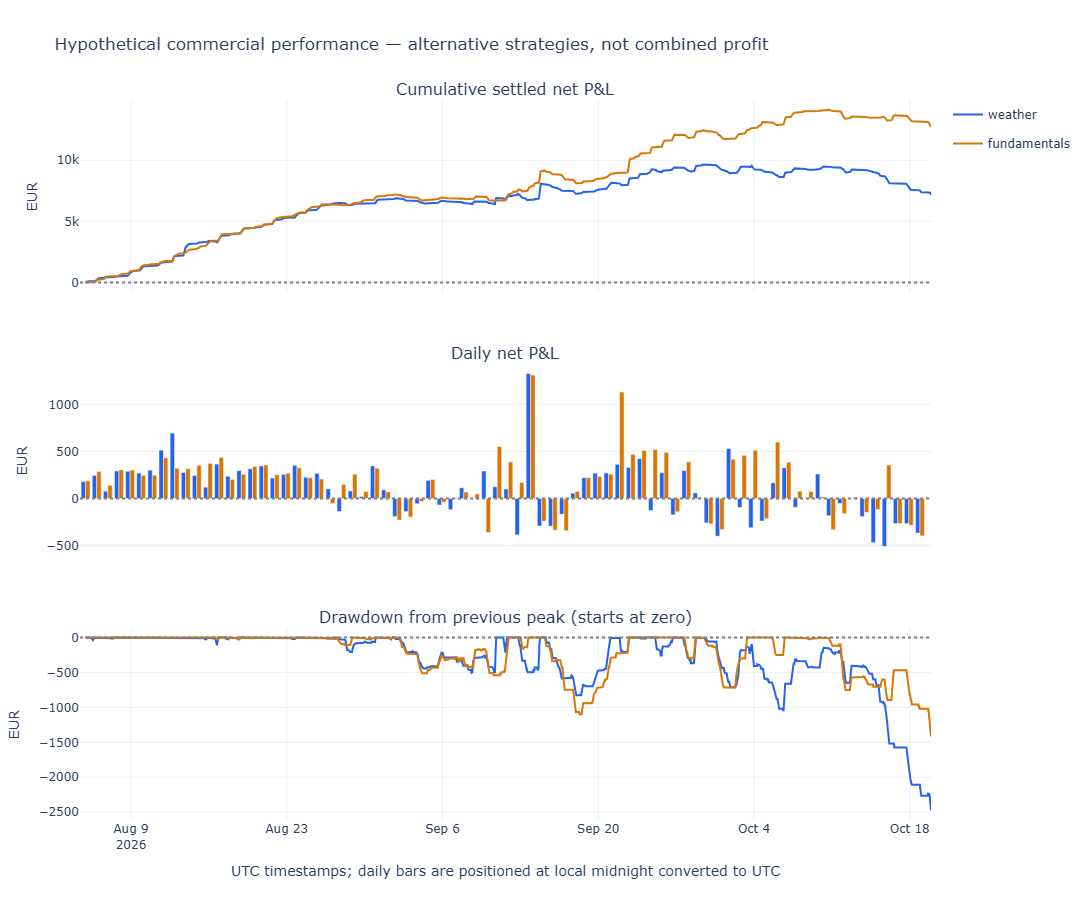

,delivery_day,net_pnl_eur,expected_net_pnl_eur,gross_volume_mwh,stress_exposure_eur,n_intervals,model
0,2026-08-05,179.933,229.966,5.0,500.0,96,weather
1,2026-08-06,244.671,220.913,5.0,500.0,96,weather
2,2026-08-07,78.144,206.090,5.0,500.0,96,weather
3,2026-08-08,293.075,381.623,5.0,500.0,96,weather
4,2026-08-09,289.647,285.394,5.0,500.0,96,weather
5,2026-08-10,269.189,236.127,5.0,500.0,96,weather
6,2026-08-11,300.521,247.490,5.0,500.0,96,weather
7,2026-08-12,514.309,343.108,5.0,500.0,96,weather
8,2026-08-13,694.613,374.137,5.0,500.0,96,weather
9,2026-08-14,276.952,237.514,5.0,500.0,96,weather


In [38]:
ledger = result['ledger']
columns = ['model','prediction','quote_mid','bid','ask','action','quantity_mwh',
           'execution_price','actual_da','fees_eur','expected_net_pnl_eur','net_pnl_eur']
display(ledger.loc[ledger.quantity_mwh.ne(0),columns].head(20).round(3))
commercial_performance_figure(result).show()
display(result['daily'].head(10).round(3))

## Prices and buy/sell decisions
Choose a **local delivery date** below. The first eligible day is shown by default, without selecting a profitable day in hindsight. Each plot shows one model's alternative strategy:

- **Black line:** actual DA settlement price, known later.
- **Blue line:** the model forecast used to decide.
- **Grey midpoint and bid/ask lines:** hypothetical counterparty quotes.
- **Green up / red down triangles:** executed buys/sells at execution prices including slippage.
- **Grey crosses:** qualifying signals that received no allocation because risk/volume capacity was exhausted.
- **Lower panels:** signed energy and realised hypothetical net P&L after fees.

Click the optional buy/sell threshold traces in the legend to display them. A buy requires the forecast to exceed ask + slippage + fee + buffer; a sell requires the forecast below bid − slippage − fee − buffer. Arrows are located at **delivery timestamps** for comparison with settlement, but the contracts were selected at the preceding-day decision time shown in the title/hover. Actual prices did not determine the arrows. No-trade intervals have zero quantity and zero P&L.

A buy arrow does not automatically mean profit: compare its execution price with actual settlement and account for fees. Sell positions benefit when settlement is sufficiently below execution.

Available local delivery days: ['2026-08-05', '2026-08-06', '2026-08-07', '2026-08-08', '2026-08-09', '2026-08-10', '2026-08-11', '2026-08-12', '2026-08-13', '2026-08-14', '2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21', '2026-08-22', '2026-08-23', '2026-08-24', '2026-08-25', '2026-08-26', '2026-08-27', '2026-08-28', '2026-08-29', '2026-08-30', '2026-08-31', '2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04', '2026-09-05', '2026-09-06', '2026-09-07', '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11', '2026-09-12', '2026-09-13', '2026-09-14', '2026-09-15', '2026-09-16', '2026-09-17', '2026-09-18', '2026-09-19', '2026-09-20', '2026-09-21', '2026-09-22', '2026-09-23', '2026-09-24', '2026-09-25', '2026-09-26', '2026-09-27', '2026-09-28', '2026-09-29', '2026-09-30', '2026-10-01', '2026-10-02', '2026-10-03', '2026-10-04', '2026-10-05', '2026-10-06', '2026-10-07', '2026-10-08', '2026-10-09', '2026-10-10', '2026-10-11', '2026-10-12', '2

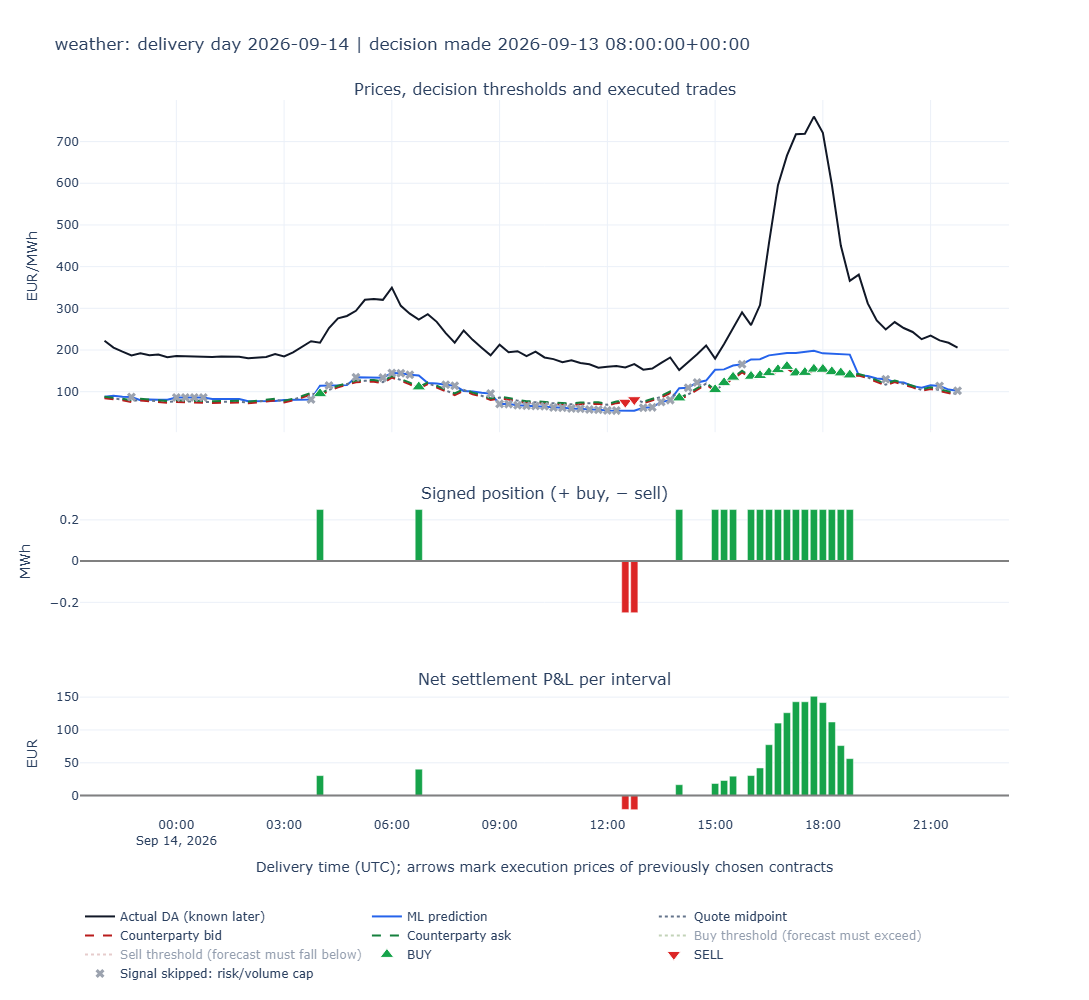

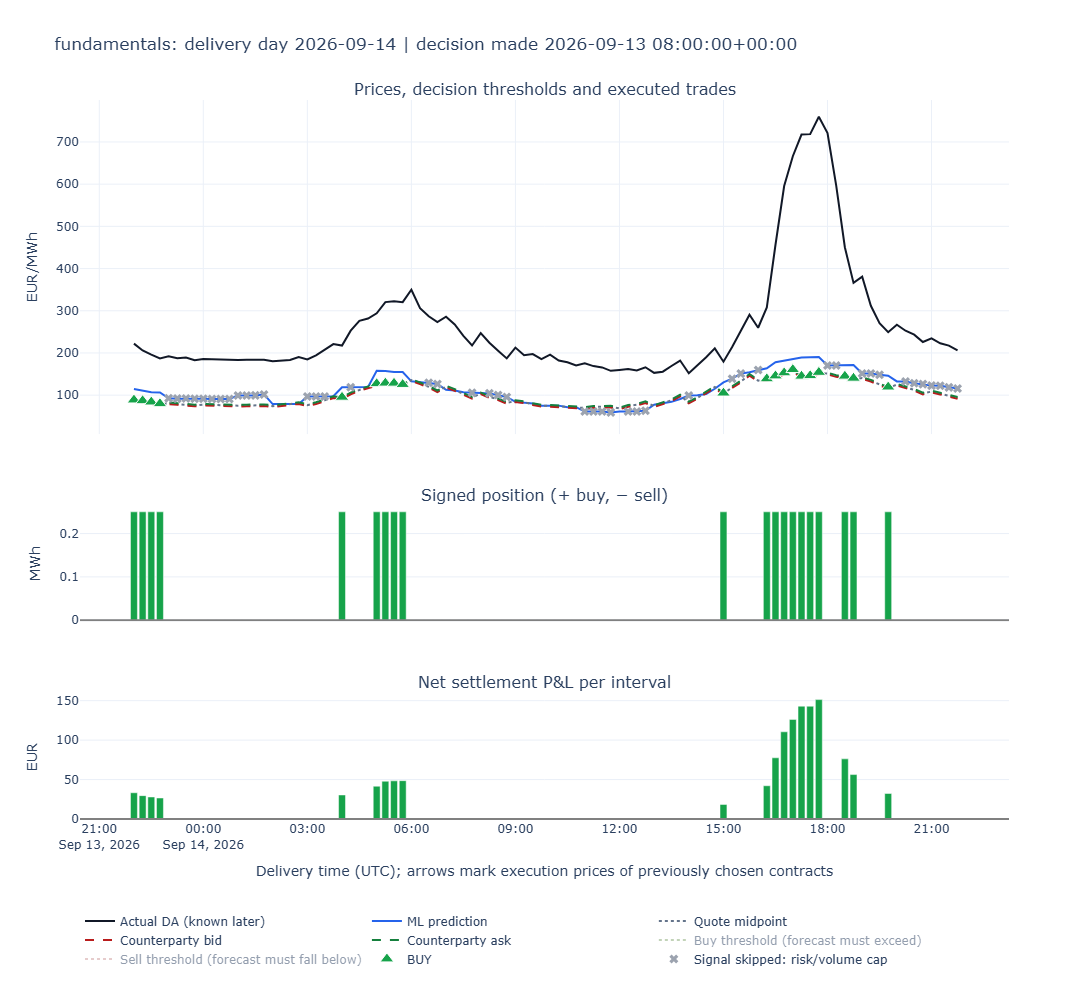

In [42]:
print('Available local delivery days:', sorted(ledger.delivery_day.unique()))
DELIVERY_DAY = '2026-09-14'  # e.g. '2026-09-14', if present; None selects first eligible day
for model in ['weather', 'fundamentals']:
    decision_figure(result, model=model, delivery_day=DELIVERY_DAY).show()

## Connect forecast quality to commercial performance
Compare high-price MAE with high-price P&L and number of trades. An accurate model may trade less because it agrees with the quote; a less accurate model can occasionally profit by chance. Evaluate the benchmark's MAE as well as the models' MAE.

Win rate counts only executed trades. Worst day includes all eligible scored days, including days with no trades. Maximum drawdown starts from zero cumulative profit and follows delivery-time settlement; it is not an intraday mark-to-market margin measure. The cash/no-trade benchmark earns zero in this simplified simulation.

All scores cover retained complete-case intervals, not necessarily every interval in a day. Missing data may bias the sample. Use a later untouched period if you change settings after examining these results.


In [43]:
display(result['regimes'].round(3))
worst = ledger.sort_values('net_pnl_eur').head(10)
display(worst[columns].round(3))

,model,regime,n_intervals,n_trades,net_pnl_eur,prediction_mae,quote_mae
0,weather,all,7295,1520,7163.838,60.282,62.419
1,weather,high_price,3429,756,4636.031,84.036,86.068
2,weather,other,3866,764,2527.807,39.213,41.444
3,fundamentals,all,7295,1520,12725.886,56.979,62.419
4,fundamentals,high_price,3429,809,9185.653,79.136,86.068
5,fundamentals,other,3866,711,3540.233,37.327,41.444


,model,prediction,quote_mid,bid,ask,action,quantity_mwh,execution_price,actual_da,fees_eur,expected_net_pnl_eur,net_pnl_eur
delivery_start_utc,,,,,,,,,,,,
2026-09-25 05:30:00+00:00,weather,99.087,123.693,121.693,125.693,SELL,-0.25,121.193,277.47,0.125,5.401,-39.194
2026-09-25 05:15:00+00:00,weather,99.181,125.631,123.631,127.631,SELL,-0.25,123.131,269.96,0.125,5.863,-36.832
2026-10-01 14:45:00+00:00,weather,60.018,109.427,107.427,111.427,SELL,-0.25,106.927,243.81,0.125,11.602,-34.346
2026-09-25 05:00:00+00:00,weather,98.663,122.995,120.995,124.995,SELL,-0.25,120.495,254.89,0.125,5.333,-33.724
2026-10-15 07:00:00+00:00,weather,88.029,117.737,115.737,119.737,SELL,-0.25,115.237,248.27,0.125,6.677,-33.383
2026-10-12 05:15:00+00:00,weather,100.161,126.076,124.076,128.076,SELL,-0.25,123.576,255.72,0.125,5.729,-33.161
2026-10-19 15:45:00+00:00,fundamentals,116.140,148.137,146.137,150.137,SELL,-0.25,145.637,274.56,0.125,7.249,-32.356
2026-10-14 17:00:00+00:00,fundamentals,118.475,161.671,159.671,163.671,SELL,-0.25,159.171,287.57,0.125,10.049,-32.225
2026-10-15 06:00:00+00:00,weather,90.864,134.673,132.673,136.673,SELL,-0.25,132.173,259.56,0.125,10.202,-31.972


## Optional cost sensitivity — descriptive, not test-set optimisation
Keep the same model forecasts and quote midpoint and vary the assumed spread. Do not select the spread or risk buffer with the highest test profit and then claim an unbiased backtest. A real spread is an execution constraint, not a free optimisation choice. This diagnostic recalculates trade selection under each assumption.


In [45]:
RUN_SENSITIVITY = True
if RUN_SENSITIVITY:
    tables = []
    for spread in [2., 4., 8., 12.]:
        scenario = run_contract(frame, metadata, replace(cfg, spread_eur_mwh=spread))
        tables.append(scenario['summary'].assign(assumed_full_spread=spread))
    sensitivity = pd.concat(tables, ignore_index=True)
    display(sensitivity[['model','assumed_full_spread','n_trades','net_pnl_eur','max_drawdown_eur']])

,model,assumed_full_spread,n_trades,net_pnl_eur,max_drawdown_eur
0,weather,2.0,1520,7543.837609,2372.320710
1,fundamentals,2.0,1520,13105.886095,1366.814688
2,weather,4.0,1520,7163.837609,2475.570710
3,fundamentals,4.0,1520,12725.886095,1415.314688
4,weather,8.0,1520,6403.837609,2682.070710
5,fundamentals,8.0,1520,11965.886095,1512.314688
6,weather,12.0,1520,5643.837609,2888.570710
7,fundamentals,12.0,1520,11205.886095,1609.314688


## Save and report honestly
Export a full trade ledger, model summary, daily results, high-price breakdown and assumptions. The forecast file checksum is retained for traceability. Do not annualise a short seasonal test or describe these hypothetical returns as achievable trading profits. The next substantive upgrades are verified pre-decision forecast vintages and observed executable contract quotes.


In [46]:
export_contract(result, OUTPUT)
export_commercial_visuals(result, OUTPUT, DELIVERY_DAY)
print(f'Saved contract evaluation to {OUTPUT.resolve()}')
for assumption in result['report']['assumptions']:
    print('-', assumption)

Saved contract evaluation to C:\Users\boons\quant\github-scripts\da_contract_project\contract_output
- Hypothetical financially settled fixed-price contracts, not exchange DA orders
- Unlimited counterparty quote availability up to configured volume; no rejection/default/collateral costs
- Frozen training-only calendar mean is quote midpoint; both models face identical bid/ask quotes
- Orders selected before observing settlement prices; actual DA used only in settlement/evaluation
- Stress budget is exposure under an assumed adverse move, not a guaranteed loss cap
- Each model is a separate alternative strategy, not a combined portfolio
- Retrospective forecast vintages are unverified; hypothetical P&L is not demonstrated achievable profit
- Only complete-case forecast rows are scored; missing periods are not imputed
- Zero-trade cash benchmark has zero P&L; no interest or funding included
